# Modelo 1 — Risco de falta em consultas agendadas

## 0. Contexto

No Acolhe+, a UBS pede ao cidadão que confirme a consulta alguns dias úteis antes.
Este modelo calcula uma **pontuação de risco de falta** para cada consulta e a classifica em
**risco baixo ou alto**. O risco define com quantos dias úteis de antecedência o
pedido de confirmação é enviado, para que vagas de quem não vai comparecer possam
ser liberadas a tempo.

- **Base:** Medical Appointment No Shows (Kaggle), com 110.527 consultas do SUS em
  Vitória (ES).
- **Alvo:** coluna `No-show`, convertida em 1 (faltou) e 0 (compareceu).
- **Tipo de problema:** classificação binária.
- **Algoritmos comparados:** Regressão Logística, Árvore de Decisão e Random Forest.

**Roteiro do notebook**
1. Instalação e importações
2. Leitura dos dados
3. Conhecendo a base
4. Limpeza e criação de variáveis
5. Histórico de faltas
6. Seleção dos atributos
7. Análise exploratória
8. Separação treino / validação / teste
9. Pré-processamento e modelos
10. Treinamento
11. Escolha do limiar
12. Avaliação no teste
13. Exemplo de previsão
14. Exportação
15. Conclusão

- **Fonte:** [base no Kaggle](https://www.kaggle.com/datasets/joniarroba/noshowappointments).

## 1. Instalação e importações

A célula importa as ferramentas usadas no notebook e cria a pasta de trabalho, com
uma subpasta para cada tipo de arquivo da entrega (dados, modelos, resultados e API).
A semente (`SEED = 42`) fixa os sorteios para que os resultados se repitam
a cada execução.

In [3]:
from pathlib import Path
import json
import shutil
import kagglehub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from google.colab import files

# Pré-processamento
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Separação dos dados
from sklearn.model_selection import StratifiedGroupKFold

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
)

BASE = Path('/content/sus-faltas')
for pasta in ['dados', 'modelos', 'resultados', 'api']:
    (BASE / pasta).mkdir(parents=True, exist_ok=True)

SEED = 42
print('Pasta de trabalho:', BASE)

Pasta de trabalho: /content/sus-faltas


## 2. Leitura dos dados

A base é baixada direto do Kaggle com a biblioteca `kagglehub`, sem upload manual,
sempre na mesma versão, para que uma atualização da base não mude os resultados.
Se a cópia do CSV já existir na pasta, ela é reaproveitada sem baixar de novo.
Uma cópia do CSV é salva em `dados/` para entrar no .zip da entrega. Os
identificadores (`PatientId` e `AppointmentID`) são lidos como texto, porque são
códigos e não quantidades.

In [4]:
VERSAO_KAGGLE = 'joniarroba/noshowappointments/versions/5'
caminho_csv = BASE / 'dados' / 'consultas_original.csv'

if not caminho_csv.exists():
    pasta_kaggle = Path(kagglehub.dataset_download(VERSAO_KAGGLE))
    print('Arquivos baixados:', [arquivo.name for arquivo in pasta_kaggle.glob('*')])
    arquivo_kaggle = next(pasta_kaggle.glob('*.csv'))
    shutil.copy(arquivo_kaggle, caminho_csv)
else:
    print('Usando a cópia local:', caminho_csv)

df_original = pd.read_csv(
    caminho_csv,
    dtype={'PatientId': str, 'AppointmentID': str}
)
df_original.columns = df_original.columns.str.strip()

print('Linhas e colunas:', df_original.shape)
display(df_original.head())

Using Colab cache for faster access to the 'noshowappointments' dataset.
Arquivos baixados: ['KaggleV2-May-2016.csv']
Linhas e colunas: (110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,29872499824296,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,558997776694438,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4262962299951,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,867951213174,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8841186448183,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


## 3. Conhecendo a base

Antes de qualquer tratamento, verificamos o tamanho da base, os tipos das
colunas, os valores ausentes, a distribuição do alvo e a faixa de idades.

In [5]:
df_original.info()

print('\nValores ausentes por coluna:')
display(df_original.isna().sum().to_frame('nulos'))

print('Distribuição do alvo:')
display(df_original['No-show'].value_counts().to_frame('consultas'))

print('Idades:')
display(df_original['Age'].describe().round(2))
print('Registros com idade negativa:', (df_original['Age'] < 0).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   PatientId       110527 non-null  object
 1   AppointmentID   110527 non-null  object
 2   Gender          110527 non-null  object
 3   ScheduledDay    110527 non-null  object
 4   AppointmentDay  110527 non-null  object
 5   Age             110527 non-null  int64 
 6   Neighbourhood   110527 non-null  object
 7   Scholarship     110527 non-null  int64 
 8   Hipertension    110527 non-null  int64 
 9   Diabetes        110527 non-null  int64 
 10  Alcoholism      110527 non-null  int64 
 11  Handcap         110527 non-null  int64 
 12  SMS_received    110527 non-null  int64 
 13  No-show         110527 non-null  object
dtypes: int64(7), object(7)
memory usage: 11.8+ MB

Valores ausentes por coluna:


,nulos
PatientId,0
AppointmentID,0
Gender,0
ScheduledDay,0
AppointmentDay,0
Age,0
Neighbourhood,0
Scholarship,0
Hipertension,0
Diabetes,0


Distribuição do alvo:


,consultas
No-show,
No,88208
Yes,22319


Idades:


,Age
count,110527.00
mean,37.09
std,23.11
min,-1.00
25%,18.00
50%,37.00
75%,55.00
max,115.00


Registros com idade negativa: 1


### 3.1 Colunas clínicas e socioeconômicas

A base traz colunas de saúde (`Hipertension`, `Diabetes`, `Alcoholism`, `Handcap`)
e a participação no Bolsa Família (`Scholarship`). A tabela abaixo mostra a taxa
de falta de quem tem e de quem não tem cada característica.

Essas colunas **não entram no modelo**, por dois motivos:
1. **Disponibilidade:** o Acolhe+ trabalha com dados de agenda, contato e respostas
   da orientação, sem acesso a prontuário ou a cadastros sociais. Um modelo que
   dependesse dessas colunas não teria como ser usado na solução.
2. **LGPD:** dados de saúde são dados pessoais sensíveis (art. 5º, II), e o
   princípio da necessidade (art. 6º, III) orienta a usar apenas os dados
   indispensáveis à finalidade. Usar condição de saúde ou benefício social para
   prever falta também poderia levar a tratar pacientes de forma desigual.

In [6]:
COLUNAS_EXCLUIDAS = ['Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'Scholarship']

falta_temporaria = df_original['No-show'].map({'Yes': 1, 'No': 0})

linhas = []
for coluna in COLUNAS_EXCLUIDAS:
    tem = df_original[coluna] > 0
    linhas.append({
        'coluna': coluna,
        'pessoas_com': tem.sum(),
        'taxa_falta_com': falta_temporaria[tem].mean(),
        'taxa_falta_sem': falta_temporaria[~tem].mean()
    })

display(pd.DataFrame(linhas).round(4))

,coluna,pessoas_com,taxa_falta_com,taxa_falta_sem
0,Hipertension,21801,0.1730,0.2090
1,Diabetes,7943,0.1800,0.2036
2,Alcoholism,3360,0.2015,0.2019
3,Handcap,2241,0.1816,0.2024
4,Scholarship,10861,0.2374,0.1981


## 4. Limpeza e criação de variáveis

As colunas originais são convertidas para nomes em português e para os tipos
corretos. Também são criadas as variáveis usadas pelo modelo:

- `antecedencia_dias`: dias entre o agendamento e a consulta;
- `dia_semana`: dia da semana da consulta (0 = segunda ... 6 = domingo), tratado
  como categoria;
- `falta`: alvo, com 1 para falta e 0 para comparecimento.

São excluídos os registros impossíveis: idade negativa e consultas com data
anterior ao próprio agendamento.

In [7]:
df = df_original.copy()

df['idade'] = df['Age']
df['sexo'] = df['Gender'].str.strip().str.upper()
df['sms_recebido'] = df['SMS_received']
df['bairro'] = df['Neighbourhood'].str.strip()
df['falta'] = df['No-show'].map({'Yes': 1, 'No': 0})

df['data_agendamento'] = pd.to_datetime(df['ScheduledDay']).dt.tz_localize(None)
df['data_consulta'] = pd.to_datetime(df['AppointmentDay']).dt.tz_localize(None)

df['antecedencia_dias'] = (
    df['data_consulta'].dt.normalize() - df['data_agendamento'].dt.normalize()
).dt.days
df['dia_semana'] = df['data_consulta'].dt.dayofweek.astype(str)

print('Idade negativa:', (df['idade'] < 0).sum())
print('Consulta antes do agendamento:', (df['antecedencia_dias'] < 0).sum())

antes = len(df)
df = df.drop_duplicates(subset='AppointmentID')
df = df[(df['idade'] >= 0) & (df['antecedencia_dias'] >= 0)].reset_index(drop=True)
print('Excluídas:', antes - len(df), '| Restantes:', len(df))

display(df[['idade', 'sexo', 'antecedencia_dias', 'dia_semana', 'sms_recebido', 'falta']].head())

Idade negativa: 1
Consulta antes do agendamento: 5
Excluídas: 6 | Restantes: 110521


,idade,sexo,antecedencia_dias,dia_semana,sms_recebido,falta
0,62,F,0,4,0,0
1,56,M,0,4,0,0
2,62,F,0,4,0,0
3,8,F,0,4,0,0
4,56,F,0,4,0,0


## 5. Histórico de faltas anteriores

Para cada consulta, contamos quantas faltas o mesmo paciente teve **antes da data
do agendamento**. Só entra o que já tinha acontecido naquele momento: se as
faltas posteriores fossem contadas, o modelo usaria uma informação do futuro, que
a UBS não teria na hora de agendar (vazamento de dados).

Passos:
1. cruzar cada consulta com todas as faltas do mesmo paciente;
2. manter só as faltas com data anterior ao dia do agendamento;
3. contar quantas sobraram para cada consulta (zero quando não houver nenhuma).

In [8]:
consultas = df[['AppointmentID', 'PatientId', 'data_agendamento']]
faltas = df.loc[df['falta'] == 1, ['PatientId', 'data_consulta']]

pares = consultas.merge(faltas, on='PatientId')
pares = pares[
    pares['data_consulta'].dt.normalize() < pares['data_agendamento'].dt.normalize()
]

contagem = pares.groupby('AppointmentID').size()
df['faltas_anteriores'] = df['AppointmentID'].map(contagem).fillna(0).astype(int)

print('Distribuição das faltas anteriores:')
display(df['faltas_anteriores'].value_counts().sort_index().to_frame('consultas'))

display(
    df.loc[df['faltas_anteriores'] > 0,
           ['PatientId', 'data_agendamento', 'faltas_anteriores', 'falta']].head()
)

Distribuição das faltas anteriores:


,consultas
faltas_anteriores,
0,100608
1,7369
2,1636
3,484
4,202
5,87
6,41
7,20
8,22


,PatientId,data_agendamento,faltas_anteriores,falta
3284,327855795244822,2016-05-12 10:26:44,1,1
3290,262168723751,2016-05-02 17:57:51,1,0
3292,765868513299323,2016-05-17 11:24:42,1,0
3293,548922834826,2016-05-24 07:26:47,1,0
3304,16821169613234,2016-05-30 11:21:13,1,0


## 6. Seleção dos atributos

Entram no modelo apenas informações que a UBS tem no momento do agendamento:

| Atributo | Tipo | Origem |
|---|---|---|
| `idade` | numérico | cadastro do cidadão |
| `sexo` | categórico | cadastro do cidadão |
| `antecedencia_dias` | numérico | data do agendamento e da consulta |
| `faixa_antecedencia` | categórico | criado a partir da antecedência |
| `dia_semana` | categórico | data da consulta |
| `sms_recebido` | numérico (0/1) | envio de lembrete |
| `faltas_anteriores` | numérico | histórico do próprio paciente |
| `bairro` | categórico | unidade de saúde do paciente |

**Faixas de antecedência:** a taxa de falta salta entre "mesmo dia" e "1 a 7 dias".
As faixas ajudam o modelo a captar esse salto, que uma variável contínua sozinha
representa mal.

**Bairro:** bairros com menos de 100 consultas são agrupados em `OUTROS`, porque têm
poucos exemplos para o modelo aprender, e uma unidade nova também cai nesse grupo. O
bairro representa fatores como distância e transporte, não uma causa da falta. Como
o risco só define a antecedência do pedido de confirmação, sem negar nem retirar
vagas, o uso não prejudica o acesso do cidadão.

**Fora do modelo:** as colunas clínicas e o Bolsa Família (seção 3.1) e os
identificadores. `PatientId` só é usado para calcular o histórico e para separar os
pacientes entre treino, validação e teste.

In [9]:
df['faixa_antecedencia'] = pd.cut(
    df['antecedencia_dias'],
    bins=[-1, 0, 7, 30, np.inf],
    labels=['mesmo_dia', '1_a_7', '8_a_30', '31_ou_mais']
).astype(str)

contagem_bairros = df['bairro'].value_counts()
bairros_raros = contagem_bairros[contagem_bairros < 100].index
df['bairro'] = df['bairro'].where(~df['bairro'].isin(bairros_raros), 'OUTROS')
BAIRROS_CONHECIDOS = sorted(df['bairro'].unique())

print('Bairros agrupados em OUTROS:', len(bairros_raros))
print('Categorias de bairro no modelo:', len(BAIRROS_CONHECIDOS))

NUMERICAS = ['idade', 'antecedencia_dias', 'sms_recebido', 'faltas_anteriores']
CATEGORICAS = ['sexo', 'faixa_antecedencia', 'dia_semana', 'bairro']
ATRIBUTOS = NUMERICAS + CATEGORICAS

display(pd.DataFrame({
    'tipo': df[ATRIBUTOS].dtypes.astype(str),
    'nulos': df[ATRIBUTOS].isna().sum()
}))

Bairros agrupados em OUTROS: 7
Categorias de bairro no modelo: 75


,tipo,nulos
idade,int64,0
antecedencia_dias,int64,0
sms_recebido,int64,0
faltas_anteriores,int64,0
sexo,object,0
faixa_antecedencia,object,0
dia_semana,object,0
bairro,object,0


## 7. Análise exploratória

Os gráficos comparam a taxa de falta entre grupos. A linha tracejada marca a taxa
geral da base: barras acima dela indicam grupos que faltam mais que a média.

,idade,antecedencia_dias,sms_recebido,faltas_anteriores
count,110521.00,110521.00,110521.00,110521.00
mean,37.09,10.18,0.32,0.13
std,23.11,15.26,0.47,0.53
min,0.00,0.00,0.00,0.00
25%,18.00,0.00,0.00,0.00
50%,37.00,4.00,0.00,0.00
75%,55.00,15.00,1.00,0.00
max,115.00,179.00,1.00,15.00


Taxa de faltas: 20.19%
Acurácia de sempre prever comparecimento: 79.81%


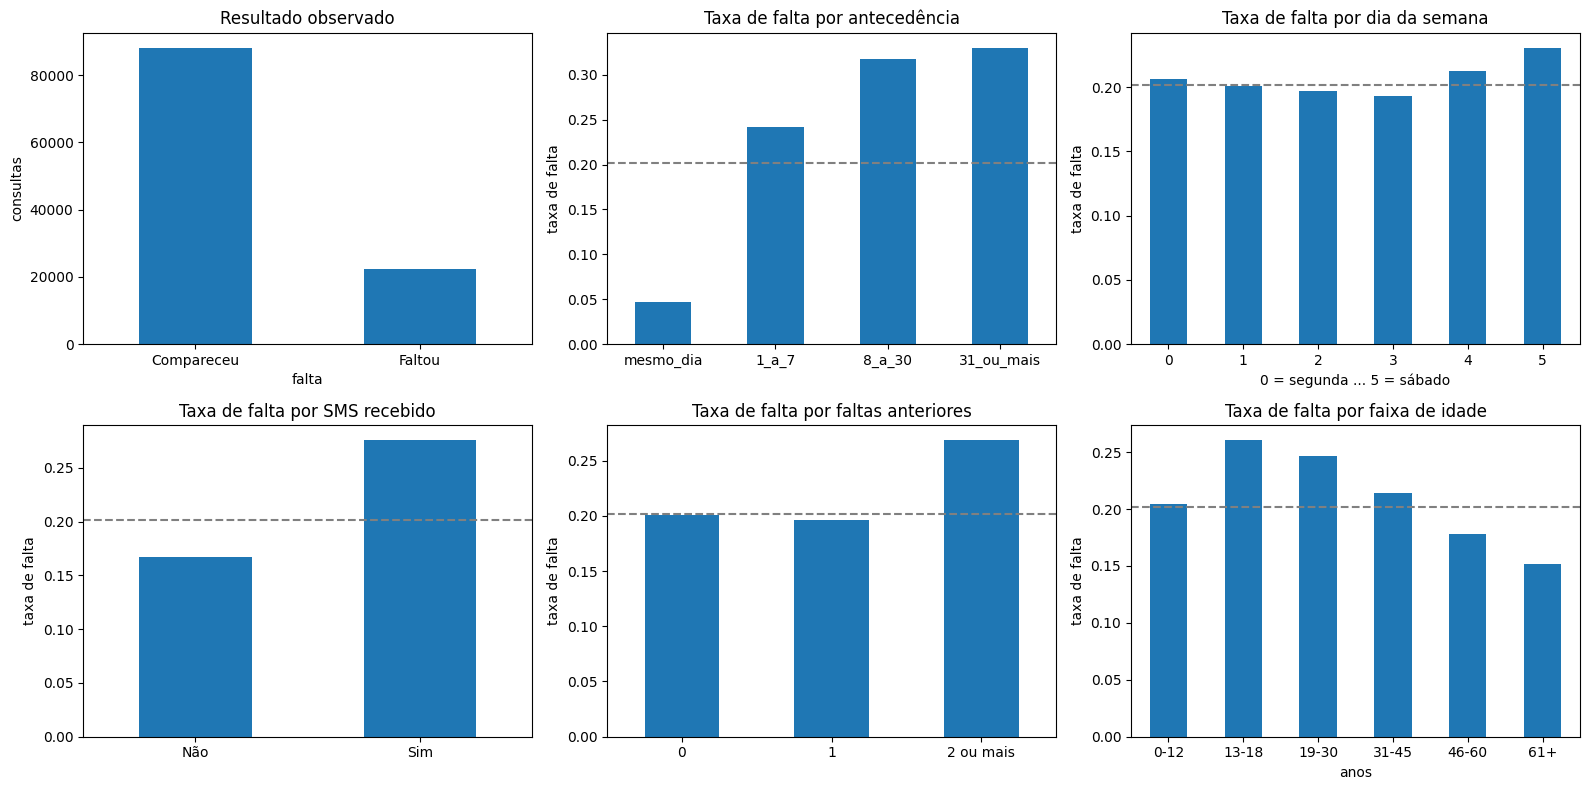

In [10]:
taxa_geral = df['falta'].mean()

display(df[NUMERICAS].describe().round(2))
print('Taxa de faltas:', f'{taxa_geral:.2%}')
print('Acurácia de sempre prever comparecimento:', f'{1 - taxa_geral:.2%}')

ordem_faixas = ['mesmo_dia', '1_a_7', '8_a_30', '31_ou_mais']
faixa_faltas = pd.cut(df['faltas_anteriores'], [-1, 0, 1, np.inf],
                      labels=['0', '1', '2 ou mais'])
faixa_idade = pd.cut(df['idade'], [-1, 12, 18, 30, 45, 60, np.inf],
                     labels=['0-12', '13-18', '19-30', '31-45', '46-60', '61+'])

fig, ax = plt.subplots(2, 3, figsize=(16, 8))

df['falta'].value_counts().reindex([0, 1]).plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].set(title='Resultado observado', ylabel='consultas')
ax[0, 0].set_xticklabels(['Compareceu', 'Faltou'])

df.groupby('faixa_antecedencia')['falta'].mean().reindex(ordem_faixas).plot.bar(ax=ax[0, 1], rot=0)
ax[0, 1].set(title='Taxa de falta por antecedência', xlabel='')

df.groupby('dia_semana')['falta'].mean().sort_index().plot.bar(ax=ax[0, 2], rot=0)
ax[0, 2].set(title='Taxa de falta por dia da semana', xlabel='0 = segunda ... 5 = sábado')

df.groupby('sms_recebido')['falta'].mean().plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].set(title='Taxa de falta por SMS recebido', xlabel='')
ax[1, 0].set_xticklabels(['Não', 'Sim'])

df.groupby(faixa_faltas, observed=True)['falta'].mean().plot.bar(ax=ax[1, 1], rot=0)
ax[1, 1].set(title='Taxa de falta por faltas anteriores', xlabel='')

df.groupby(faixa_idade, observed=True)['falta'].mean().plot.bar(ax=ax[1, 2], rot=0)
ax[1, 2].set(title='Taxa de falta por faixa de idade', xlabel='anos')

for eixo in ax.flat[1:]:
    eixo.axhline(taxa_geral, color='gray', linestyle='--')
    eixo.set_ylabel('taxa de falta')

plt.tight_layout()
plt.savefig(BASE / 'resultados' / 'exploracao.png', dpi=150)
plt.show()

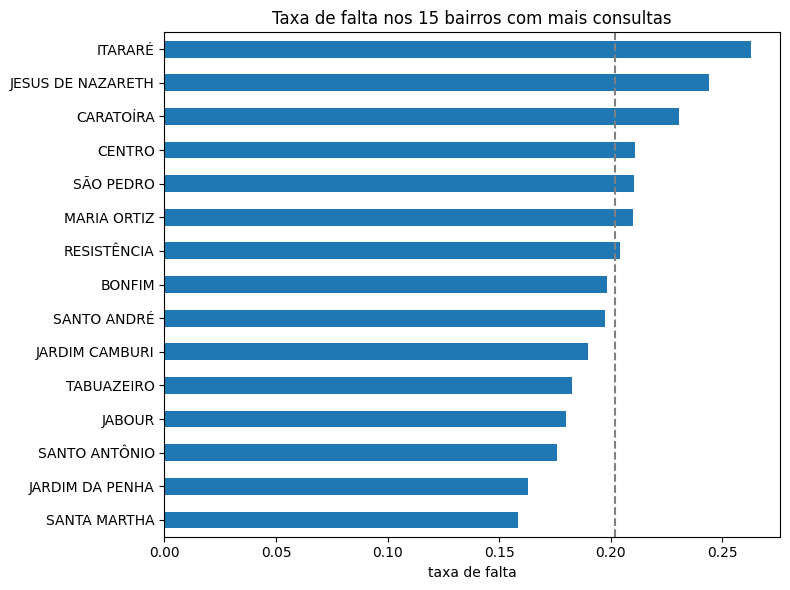

In [11]:
principais = df['bairro'].value_counts().head(15).index
taxa_bairro = (
    df[df['bairro'].isin(principais)]
    .groupby('bairro')['falta'].mean()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 6))
taxa_bairro.plot.barh(ax=ax)
ax.axvline(taxa_geral, color='gray', linestyle='--')
ax.set(title='Taxa de falta nos 15 bairros com mais consultas',
       xlabel='taxa de falta', ylabel='')
plt.tight_layout()
plt.savefig(BASE / 'resultados' / 'exploracao_bairros.png', dpi=150)
plt.show()

In [12]:
por_faixa = df.groupby('faixa_antecedencia')['falta'].mean()
por_sms = df.groupby('sms_recebido')['falta'].mean()
por_historico = df.groupby(faixa_faltas, observed=True)['falta'].mean()

display(Markdown(f"""
### Principais observações

1. **Antecedência.** Consultas marcadas para o mesmo dia tiveram
   **{por_faixa['mesmo_dia']:.1%}** de falta, contra **{por_faixa['31_ou_mais']:.1%}**
   nas marcadas com 31 dias ou mais. Agendas abertas com muita antecedência
   concentram as faltas, e isso reforça o pedido de confirmação.

2. **SMS.** Quem recebeu SMS faltou **{por_sms[1]:.1%}**, contra **{por_sms[0]:.1%}**
   de quem não recebeu. O resultado parece contraditório, mas o SMS costuma ser
   enviado para consultas marcadas com mais antecedência, que já faltam mais. A
   base não permite concluir que o SMS aumenta as faltas, o que mostra que
   associação não é causalidade.

3. **Histórico.** Pacientes sem faltas anteriores faltaram **{por_historico['0']:.1%}**,
   e pacientes com 2 ou mais faltas, **{por_historico['2 ou mais']:.1%}**.

A base tem **{len(df)} consultas** e taxa geral de falta de **{taxa_geral:.1%}**.
Um modelo que sempre previsse comparecimento teria **{1 - taxa_geral:.1%}** de
acurácia sem identificar nenhuma falta, e por isso a acurácia não é a métrica
principal deste trabalho.
"""))


### Principais observações

1. **Antecedência.** Consultas marcadas para o mesmo dia tiveram
   **4.6%** de falta, contra **33.0%**
   nas marcadas com 31 dias ou mais. Agendas abertas com muita antecedência
   concentram as faltas, e isso reforça o pedido de confirmação.

2. **SMS.** Quem recebeu SMS faltou **27.6%**, contra **16.7%**
   de quem não recebeu. O resultado parece contraditório, mas o SMS costuma ser
   enviado para consultas marcadas com mais antecedência, que já faltam mais. A
   base não permite concluir que o SMS aumenta as faltas, o que mostra que
   associação não é causalidade.

3. **Histórico.** Pacientes sem faltas anteriores faltaram **20.1%**,
   e pacientes com 2 ou mais faltas, **26.8%**.

A base tem **110521 consultas** e taxa geral de falta de **20.2%**.
Um modelo que sempre previsse comparecimento teria **79.8%** de
acurácia sem identificar nenhuma falta, e por isso a acurácia não é a métrica
principal deste trabalho.


## 8. Separação treino / validação / teste

A base é dividida em três partes:

- **treino (60%)**: usado para o modelo aprender;
- **validação (20%)**: usada para comparar os algoritmos e escolher o limiar;
- **teste (20%)**: usado uma única vez, no fim, para medir o desempenho final.

Dois cuidados:
1. **Separação por paciente:** o mesmo paciente aparece em várias consultas. Se ele
   estivesse no treino e no teste ao mesmo tempo, o modelo poderia "reconhecê-lo", e
   o resultado ficaria melhor do que na vida real. Por isso, cada paciente fica em
   uma única parte.
2. **Estratificação:** cada parte mantém a mesma proporção de faltas (cerca de 20%).

O `StratifiedGroupKFold` faz as duas coisas: divide em grupos (pacientes) mantendo a
proporção do alvo. Com 5 partes, uma vira teste (20%); o restante é dividido de
novo em 4 partes, e uma vira validação (20% do total).

In [13]:
X = df[ATRIBUTOS]
y = df['falta']
pacientes = df['PatientId']

divisao_teste = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_resto, idx_teste = next(divisao_teste.split(X, y, pacientes))

divisao_validacao = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
pos_treino, pos_validacao = next(divisao_validacao.split(
    X.iloc[idx_resto], y.iloc[idx_resto], pacientes.iloc[idx_resto]
))
idx_treino = idx_resto[pos_treino]
idx_validacao = idx_resto[pos_validacao]

X_treino, y_treino = X.iloc[idx_treino], y.iloc[idx_treino]
X_validacao, y_validacao = X.iloc[idx_validacao], y.iloc[idx_validacao]
X_teste, y_teste = X.iloc[idx_teste], y.iloc[idx_teste]

p_treino = set(pacientes.iloc[idx_treino])
p_validacao = set(pacientes.iloc[idx_validacao])
p_teste = set(pacientes.iloc[idx_teste])
print('Pacientes repetidos entre as partes:',
      len(p_treino & p_validacao) + len(p_treino & p_teste) + len(p_validacao & p_teste))

for nome, rotulo in [('Treino', y_treino), ('Validação', y_validacao), ('Teste', y_teste)]:
    print(f'{nome}: {len(rotulo)} consultas | faltas: {rotulo.mean():.2%}')

Pacientes repetidos entre as partes: 0
Treino: 66179 consultas | faltas: 20.15%
Validação: 22253 consultas | faltas: 20.20%
Teste: 22089 consultas | faltas: 20.30%


## 9. Pré-processamento e modelos

Cada modelo é um **Pipeline** com duas etapas:
1. **Pré-processamento:** as variáveis numéricas são padronizadas (`StandardScaler`)
   e as categóricas viram colunas 0/1 (`OneHotEncoder`). Uma categoria que não
   apareceu no treino é ignorada, sem gerar erro.
2. **Classificador:** um dos três algoritmos comparados.

Como o pré-processamento fica dentro do Pipeline, ele é salvo junto com o modelo e a
API recebe os dados no formato original.

| Algoritmo | Por que testar |
|---|---|
| Regressão Logística | modelo simples e interpretável, usado como referência |
| Árvore de Decisão | capta regras do tipo "se antecedência > X e já faltou..." |
| Random Forest | combina várias árvores e costuma errar menos que uma árvore só |

Os três usam `class_weight='balanced'`: como só 20% das consultas são faltas, os erros
na classe falta recebem peso maior, para o modelo não aprender a prever sempre
"compareceu".

In [14]:
def criar_preprocessamento(numericas, categoricas):
    return ColumnTransformer([
        ('numericas', StandardScaler(), numericas),
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas)
    ])


def criar_modelos(numericas, categoricas):
    return {
        'Regressão Logística': Pipeline([
            ('preprocessamento', criar_preprocessamento(numericas, categoricas)),
            ('classificador', LogisticRegression(
                max_iter=2000, class_weight='balanced', random_state=SEED))
        ]),
        'Árvore de Decisão': Pipeline([
            ('preprocessamento', criar_preprocessamento(numericas, categoricas)),
            ('classificador', DecisionTreeClassifier(
                max_depth=8, min_samples_leaf=50,
                class_weight='balanced', random_state=SEED))
        ]),
        'Random Forest': Pipeline([
            ('preprocessamento', criar_preprocessamento(numericas, categoricas)),
            ('classificador', RandomForestClassifier(
                n_estimators=100, max_depth=10, min_samples_leaf=20,
                class_weight='balanced', n_jobs=-1, random_state=SEED))
        ])
    }

print('Função de modelos pronta.')

Função de modelos pronta.


## 10. Treinamento

Os três algoritmos são treinados duas vezes: **com** e **sem** o atributo `bairro`.
A comparação usa a **ROC-AUC na validação**, que mede o quanto o modelo separa quem
falta de quem comparece, sem depender do limiar escolhido (0,5 = acaso; 1,0 =
separação perfeita). O conjunto de atributos com o melhor resultado segue para as
próximas etapas.

In [15]:
conjuntos = {
    'com bairro': (NUMERICAS, CATEGORICAS),
    'sem bairro': (NUMERICAS, [c for c in CATEGORICAS if c != 'bairro'])
}

modelos_treinados = {}
linhas = []

for nome_conjunto, (numericas, categoricas) in conjuntos.items():
    for nome_modelo, modelo in criar_modelos(numericas, categoricas).items():
        print('Treinando:', nome_modelo, '|', nome_conjunto)
        modelo.fit(X_treino, y_treino)
        probabilidades = modelo.predict_proba(X_validacao)[:, 1]

        modelos_treinados[(nome_conjunto, nome_modelo)] = modelo
        linhas.append({
            'modelo': nome_modelo,
            'atributos': nome_conjunto,
            'roc_auc': roc_auc_score(y_validacao, probabilidades)
        })

comparacao_atributos = pd.DataFrame(linhas).pivot(
    index='modelo', columns='atributos', values='roc_auc'
)
comparacao_atributos['diferenca'] = (
    comparacao_atributos['com bairro'] - comparacao_atributos['sem bairro']
)
print('\nROC-AUC na validação:')
display(comparacao_atributos.round(4))

conjunto_escolhido = 'com bairro' if comparacao_atributos['diferenca'].max() > 0 else 'sem bairro'
NUMERICAS_MODELO, CATEGORICAS_MODELO = conjuntos[conjunto_escolhido]
ATRIBUTOS_MODELO = NUMERICAS_MODELO + CATEGORICAS_MODELO

modelos = {
    nome: modelos_treinados[(conjunto_escolhido, nome)]
    for nome in ['Regressão Logística', 'Árvore de Decisão', 'Random Forest']
}
print('Conjunto escolhido:', conjunto_escolhido)
print('Atributos do modelo:', ATRIBUTOS_MODELO)

Treinando: Regressão Logística | com bairro
Treinando: Árvore de Decisão | com bairro
Treinando: Random Forest | com bairro
Treinando: Regressão Logística | sem bairro
Treinando: Árvore de Decisão | sem bairro
Treinando: Random Forest | sem bairro

ROC-AUC na validação:


atributos,com bairro,sem bairro,diferenca
modelo,,,
Random Forest,0.7282,0.7285,-0.0002
Regressão Logística,0.7221,0.7189,0.0032
Árvore de Decisão,0.7234,0.7196,0.0038


Conjunto escolhido: com bairro
Atributos do modelo: ['idade', 'antecedencia_dias', 'sms_recebido', 'faltas_anteriores', 'sexo', 'faixa_antecedencia', 'dia_semana', 'bairro']


## 11. Escolha do modelo e do limiar

**Modelo:** é escolhido pela maior ROC-AUC na validação.

**Limiar:** a probabilidade vira risco **alto** quando passa do limiar. Um limiar
baixo encontra mais faltas (recall maior), mas marca muitas consultas como alto, e
o "alto" perde o sentido para a recepção. Um limiar alto deixa a classificação mais
precisa, mas deixa passar faltas.

Regra adotada: entre os limiares de 0,30 a 0,80, escolhemos o de **maior F1**,
desde que no máximo **40% das consultas** fiquem como risco alto. Assim, o grupo de
risco alto continua sendo uma prioridade para a recepção, e não metade da agenda.

Se nenhum limiar de um modelo respeitar esse máximo, usamos o que marca menos
consultas como risco alto e registramos que a regra não foi atendida.

**Observação:** com `class_weight='balanced'`, a saída do modelo é uma **pontuação
de risco** entre 0 e 1, e não uma porcentagem real de chance de falta. Uma pontuação
de 0,60 indica risco maior que 0,40, mas não significa "60% de chance de faltar".

In [16]:
def avaliar(y_real, probabilidades, limiar):
    previsto = (probabilidades >= limiar).astype(int)
    return {
        'limiar': limiar,
        'consultas_alto': previsto.mean(),
        'acuracia': accuracy_score(y_real, previsto),
        'precisao': precision_score(y_real, previsto, zero_division=0),
        'recall': recall_score(y_real, previsto, zero_division=0),
        'f1': f1_score(y_real, previsto, zero_division=0),
        'roc_auc': roc_auc_score(y_real, probabilidades)
    }

In [17]:
MAXIMO_ALTO = 0.40
limiares_testados = np.round(np.arange(0.30, 0.81, 0.05), 2)

tabelas_limiar = {}
resultados_validacao = []

for nome, modelo in modelos.items():
    probabilidades = modelo.predict_proba(X_validacao)[:, 1]
    tabela = pd.DataFrame([
        avaliar(y_validacao, probabilidades, limiar) for limiar in limiares_testados
    ])
    tabelas_limiar[nome] = tabela

    permitidos = tabela[tabela['consultas_alto'] <= MAXIMO_ALTO]
    if permitidos.empty:
        print(f'{nome}: nenhum limiar deixou no máximo {MAXIMO_ALTO:.0%} como alto; '
              'usando o que marca menos consultas.')
        melhor = tabela.sort_values(['consultas_alto', 'f1'], ascending=[True, False]).iloc[0]
    else:
        melhor = permitidos.sort_values('f1', ascending=False).iloc[0]
    resultados_validacao.append({'modelo': nome, **melhor.to_dict()})

comparacao_validacao = (
    pd.DataFrame(resultados_validacao)
    .sort_values('roc_auc', ascending=False)
    .reset_index(drop=True)
)
print('Melhor limiar de cada modelo (validação):')
display(comparacao_validacao.round(4))

nome_escolhido = comparacao_validacao.loc[0, 'modelo']
modelo_final = modelos[nome_escolhido]
limiar_final = float(comparacao_validacao.loc[0, 'limiar'])

print('Modelo escolhido:', nome_escolhido)
print('Limiar escolhido:', limiar_final)
print(f'\nTodos os limiares testados — {nome_escolhido} (validação):')
display(tabelas_limiar[nome_escolhido].round(4))

Melhor limiar de cada modelo (validação):


,modelo,limiar,consultas_alto,acuracia,precisao,recall,f1,roc_auc
0,Random Forest,0.6,0.2955,0.7106,0.3521,0.5151,0.4183,0.7282
1,Árvore de Decisão,0.6,0.3668,0.6737,0.3304,0.6001,0.4262,0.7234
2,Regressão Logística,0.6,0.3438,0.6852,0.3358,0.5717,0.4231,0.7221


Modelo escolhido: Random Forest
Limiar escolhido: 0.6

Todos os limiares testados — Random Forest (validação):


,limiar,consultas_alto,acuracia,precisao,recall,f1,roc_auc
0,0.30,0.6590,0.5156,0.2857,0.9321,0.4373,0.7282
1,0.35,0.6572,0.5167,0.2859,0.9306,0.4375,0.7282
2,0.40,0.6556,0.5171,0.2858,0.9277,0.4369,0.7282
3,0.45,0.6550,0.5173,0.2857,0.9266,0.4367,0.7282
4,0.50,0.6297,0.5336,0.2900,0.9043,0.4392,0.7282
5,0.55,0.5114,0.6034,0.3097,0.7844,0.4441,0.7282
6,0.60,0.2955,0.7106,0.3521,0.5151,0.4183,0.7282
7,0.65,0.1575,0.7611,0.3827,0.2984,0.3353,0.7282
8,0.70,0.0102,0.7976,0.4779,0.0240,0.0458,0.7282
9,0.75,0.0000,0.7980,0.0000,0.0000,0.0000,0.7282


## 12. Avaliação no teste

Os três modelos são aplicados uma única vez ao conjunto de teste, cada um com o
limiar escolhido na validação. Como referência, a tabela inclui um modelo que
sempre prevê "compareceu": ele tem acurácia alta, mas não encontra nenhuma falta.

- **Matriz de confusão:** mostra acertos e erros em cada classe. Para a UBS, o erro
  mais custoso é o falso negativo (o paciente falta e não estava como risco alto).
- **Curva ROC:** mostra o desempenho em todos os limiares possíveis. Quanto mais a
  curva se afasta da diagonal (acaso), melhor o modelo separa as duas classes.

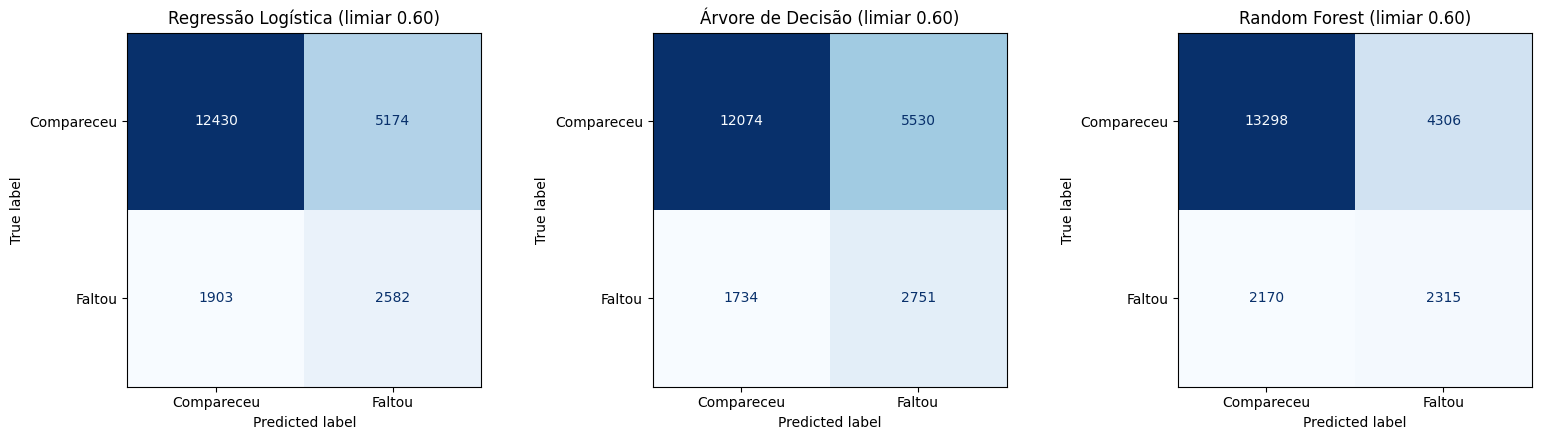

Resultados no teste:


,modelo,limiar,consultas_alto,acuracia,precisao,recall,f1,roc_auc
0,Regressão Logística,0.6,0.3511,0.6796,0.3329,0.5757,0.4219,0.7168
1,Árvore de Decisão,0.6,0.3749,0.6711,0.3322,0.6134,0.4310,0.7199
2,Random Forest,0.6,0.2997,0.7068,0.3496,0.5162,0.4169,0.7225
3,"Sempre ""compareceu""",NaN,0.0000,0.7970,0.0000,0.0000,0.0000,0.5000


In [18]:
limiares_validacao = comparacao_validacao.set_index('modelo')['limiar']

resultados_teste = []
probabilidades_teste = {}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for eixo, (nome, modelo) in zip(ax, modelos.items()):
    probabilidades = modelo.predict_proba(X_teste)[:, 1]
    limiar = float(limiares_validacao[nome])
    probabilidades_teste[nome] = probabilidades
    resultados_teste.append({'modelo': nome, **avaliar(y_teste, probabilidades, limiar)})

    ConfusionMatrixDisplay.from_predictions(
        y_teste, (probabilidades >= limiar).astype(int),
        labels=[0, 1], display_labels=['Compareceu', 'Faltou'],
        ax=eixo, colorbar=False, cmap='Blues'
    )
    eixo.set_title(f'{nome} (limiar {limiar:.2f})')

plt.tight_layout()
plt.savefig(BASE / 'resultados' / 'matrizes_confusao.png', dpi=150)
plt.show()

referencia = {
    'modelo': 'Sempre "compareceu"', 'limiar': np.nan, 'consultas_alto': 0.0,
    'acuracia': 1 - y_teste.mean(), 'precisao': 0.0, 'recall': 0.0,
    'f1': 0.0, 'roc_auc': 0.5
}
comparacao_teste = pd.DataFrame(resultados_teste + [referencia])
print('Resultados no teste:')
display(comparacao_teste.round(4))

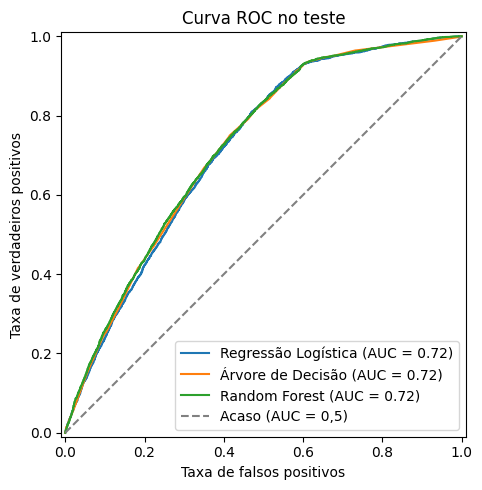

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
for nome, probabilidades in probabilidades_teste.items():
    RocCurveDisplay.from_predictions(y_teste, probabilidades, name=nome, ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Acaso (AUC = 0,5)')
ax.set(title='Curva ROC no teste',
       xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos')
ax.legend()
plt.tight_layout()
plt.savefig(BASE / 'resultados' / 'curva_roc.png', dpi=150)
plt.show()

In [20]:
metricas = ['consultas_alto', 'acuracia', 'precisao', 'recall', 'f1', 'roc_auc']
lado_a_lado = pd.DataFrame({
    'validação': comparacao_validacao.set_index('modelo').loc[nome_escolhido, metricas],
    'teste': comparacao_teste.set_index('modelo').loc[nome_escolhido, metricas]
}).astype(float)
lado_a_lado['diferença'] = lado_a_lado['teste'] - lado_a_lado['validação']

print('Modelo escolhido:', nome_escolhido)
display(lado_a_lado.round(4))

Modelo escolhido: Random Forest


,validação,teste,diferença
consultas_alto,0.2955,0.2997,0.0043
acuracia,0.7106,0.7068,-0.0038
precisao,0.3521,0.3496,-0.0024
recall,0.5151,0.5162,0.0010
f1,0.4183,0.4169,-0.0014
roc_auc,0.7282,0.7225,-0.0057


## 13. Exemplo de previsão

A função abaixo faz o mesmo caminho que a API Flask vai fazer: recebe os dados de
uma consulta, cria a faixa de antecedência, troca bairros desconhecidos por
`OUTROS`, calcula a pontuação de risco e define a antecedência do pedido de
confirmação.

Regra do Acolhe+: risco **alto** → confirmação pedida **3 dias úteis** antes;
risco **baixo** → **2 dias úteis** antes.

In [21]:
CONFIRMACAO_DIAS_UTEIS = {'alto': 3, 'baixo': 2}


def faixa_da_antecedencia(dias):
    if dias == 0:
        return 'mesmo_dia'
    elif dias <= 7:
        return '1_a_7'
    elif dias <= 30:
        return '8_a_30'
    return '31_ou_mais'


def classificar_consulta(dados):
    consulta = dict(dados)
    consulta['sexo'] = str(consulta['sexo']).strip().upper()
    consulta['dia_semana'] = str(consulta['dia_semana'])
    consulta['faixa_antecedencia'] = faixa_da_antecedencia(consulta['antecedencia_dias'])

    bairro = str(consulta.get('bairro', 'OUTROS')).strip().upper()
    consulta['bairro'] = bairro if bairro in BAIRROS_CONHECIDOS else 'OUTROS'

    entrada = pd.DataFrame([consulta])[ATRIBUTOS_MODELO]
    pontuacao = float(modelo_final.predict_proba(entrada)[0, 1])
    risco = 'alto' if pontuacao >= limiar_final else 'baixo'

    return {
        'pontuacao_risco': round(pontuacao, 4),
        'risco': risco,
        'limiar': limiar_final,
        'confirmacao_dias_uteis': CONFIRMACAO_DIAS_UTEIS[risco]
    }


exemplos = [
    {'idade': 35, 'sexo': 'F', 'antecedencia_dias': 0, 'dia_semana': '1',
     'sms_recebido': 0, 'faltas_anteriores': 0, 'bairro': 'JARDIM CAMBURI'},
    {'idade': 22, 'sexo': 'M', 'antecedencia_dias': 40, 'dia_semana': '0',
     'sms_recebido': 1, 'faltas_anteriores': 2, 'bairro': 'BAIRRO NOVO DE SP'}
]

for exemplo in exemplos:
    print('Entrada:', exemplo)
    print('Saída:  ', json.dumps(classificar_consulta(exemplo), ensure_ascii=False))
    print()

Entrada: {'idade': 35, 'sexo': 'F', 'antecedencia_dias': 0, 'dia_semana': '1', 'sms_recebido': 0, 'faltas_anteriores': 0, 'bairro': 'JARDIM CAMBURI'}
Saída:   {"pontuacao_risco": 0.1474, "risco": "baixo", "limiar": 0.6, "confirmacao_dias_uteis": 2}

Entrada: {'idade': 22, 'sexo': 'M', 'antecedencia_dias': 40, 'dia_semana': '0', 'sms_recebido': 1, 'faltas_anteriores': 2, 'bairro': 'BAIRRO NOVO DE SP'}
Saída:   {"pontuacao_risco": 0.6747, "risco": "alto", "limiar": 0.6, "confirmacao_dias_uteis": 3}



## 14. Exportação do modelo

O modelo escolhido é salvo com `joblib` em um pacote que reúne tudo o que a API
precisa: o Pipeline (pré-processamento + classificador), a lista de atributos, o
limiar, os bairros conhecidos, a regra de confirmação e as métricas do teste.

As versões do scikit-learn, do NumPy, do pandas e do joblib também são registradas,
porque a API precisa usar as mesmas versões para carregar o arquivo (elas vão para o
`requirements.txt` da API). Ao final, o arquivo é carregado de novo e as pontuações
são comparadas com as do modelo em memória, para garantir que ele não está corrompido.

In [22]:
import sklearn
import importlib.metadata

pacote = {
    'modelo': modelo_final,
    'nome_modelo': nome_escolhido,
    'atributos': ATRIBUTOS_MODELO,
    'limiar': limiar_final,
    'bairros_conhecidos': BAIRROS_CONHECIDOS,
    'confirmacao_dias_uteis': CONFIRMACAO_DIAS_UTEIS,
    'metricas_teste': comparacao_teste.set_index('modelo').loc[nome_escolhido].to_dict(),
    'versao_sklearn': sklearn.__version__,
    'versoes': {nome: importlib.metadata.version(nome)
                for nome in ['scikit-learn', 'numpy', 'pandas', 'joblib']}
}

caminho_modelo = BASE / 'modelos' / 'modelo_falta.joblib'
joblib.dump(pacote, caminho_modelo)
print('Salvo:', caminho_modelo)
print('Tamanho:', round(caminho_modelo.stat().st_size / 1024 / 1024, 2), 'MB')
print('Versão do scikit-learn:', sklearn.__version__)

carregado = joblib.load(caminho_modelo)
entrada_teste = X_teste.head(5)[carregado['atributos']]
np.testing.assert_allclose(
    modelo_final.predict_proba(entrada_teste)[:, 1],
    carregado['modelo'].predict_proba(entrada_teste)[:, 1]
)
assert carregado['limiar'] == limiar_final
print('Arquivo conferido: mesmas pontuações e mesmo limiar do modelo em memória.')
print('Versões:', carregado['versoes'])
print('\nTeste do arquivo salvo:')
print('Modelo:', carregado['nome_modelo'], '| limiar:', carregado['limiar'])
print('Pontuações de 5 consultas do teste:',
      carregado['modelo'].predict_proba(entrada_teste)[:, 1].round(4))

files.download(str(caminho_modelo))
files.download(str(caminho_csv))

Salvo: /content/sus-faltas/modelos/modelo_falta.joblib
Tamanho: 1.77 MB
Versão do scikit-learn: 1.6.1
Arquivo conferido: mesmas pontuações e mesmo limiar do modelo em memória.
Versões: {'scikit-learn': '1.6.1', 'numpy': '2.4.6', 'pandas': '2.2.3', 'joblib': '1.6.0'}

Teste do arquivo salvo:
Modelo: Random Forest | limiar: 0.6
Pontuações de 5 consultas do teste: [0.1257 0.1647 0.1293 0.5826 0.5798]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Conclusão

In [23]:
r = comparacao_teste.set_index('modelo').loc[nome_escolhido]
ref = comparacao_teste.set_index('modelo').loc['Sempre "compareceu"']

display(Markdown(f"""
**Modelo escolhido:** {nome_escolhido}, com os atributos **{conjunto_escolhido}** e
limiar de **{limiar_final:.2f}**.

**Desempenho no teste:**
- ROC-AUC de **{r['roc_auc']:.3f}** (0,5 seria o acaso);
- recall de **{r['recall']:.1%}**: proporção das faltas reais que ficaram como risco alto;
- precisão de **{r['precisao']:.1%}**: proporção das consultas de risco alto que de fato
  tiveram falta;
- **{r['consultas_alto']:.1%}** das consultas classificadas como risco alto.

A acurácia de **{r['acuracia']:.1%}** é menor que a do modelo que sempre prevê
comparecimento (**{ref['acuracia']:.1%}**), mas esse modelo não encontra nenhuma falta.
O modelo proposto aceita alguns alarmes falsos para identificar a maior parte das
faltas, o que é adequado ao uso no Acolhe+: um pedido de confirmação antecipado tem
custo baixo, enquanto uma falta não prevista deixa a vaga ociosa.

**Uso na solução:** o risco define a antecedência do pedido de confirmação
(3 dias úteis para risco alto, 2 para baixo). O risco não nega nem retira vagas.

**Limitações:**
- a base cobre poucos meses e uma única cidade (Vitória/ES), e por isso o histórico de
  faltas é curto e os bairros não se aplicam a outras cidades;
- faltar depende de fatores que não estão nos dados (transporte, trabalho, esquecimento);
- a saída é uma pontuação de risco, e não uma probabilidade calibrada;
- a avaliação é retrospectiva; em uso real, o modelo deveria ser reavaliado com dados
  da própria UBS.
"""))


**Modelo escolhido:** Random Forest, com os atributos **com bairro** e
limiar de **0.60**.

**Desempenho no teste:**
- ROC-AUC de **0.723** (0,5 seria o acaso);
- recall de **51.6%**: proporção das faltas reais que ficaram como risco alto;
- precisão de **35.0%**: proporção das consultas de risco alto que de fato
  tiveram falta;
- **30.0%** das consultas classificadas como risco alto.

A acurácia de **70.7%** é menor que a do modelo que sempre prevê
comparecimento (**79.7%**), mas esse modelo não encontra nenhuma falta.
O modelo proposto aceita alguns alarmes falsos para identificar a maior parte das
faltas, o que é adequado ao uso no Acolhe+: um pedido de confirmação antecipado tem
custo baixo, enquanto uma falta não prevista deixa a vaga ociosa.

**Uso na solução:** o risco define a antecedência do pedido de confirmação
(3 dias úteis para risco alto, 2 para baixo). O risco não nega nem retira vagas.

**Limitações:**
- a base cobre poucos meses e uma única cidade (Vitória/ES), e por isso o histórico de
  faltas é curto e os bairros não se aplicam a outras cidades;
- faltar depende de fatores que não estão nos dados (transporte, trabalho, esquecimento);
- a saída é uma pontuação de risco, e não uma probabilidade calibrada;
- a avaliação é retrospectiva; em uso real, o modelo deveria ser reavaliado com dados
  da própria UBS.
